# Implementasi Linear Classifier (Single Layer Perceptron) pada Dataset Iris
### Klasifikasi Iris Setosa (0) vs Iris Versicolor (1)

**Nama:** Frans Alwan Purba  
**NIM:** _(25/563545/PPA/07116)_

---

### Konfigurasi Model (sesuai sheet "Konfigurasi Model")

| Parameter | Nilai |
|---|---|
| Neuron input | 4 (SepalLength, SepalWidth, PetalLength, PetalWidth) |
| Neuron output | 1 (binary encoding) |
| Target | Setosa = 0, Versicolor = 1 |
| Bobot awal teta1–teta4 | 0.5 |
| Bias awal | 0.5 |
| Learning Rate | 0.1 |
| Aktivasi | Sigmoid, g(z) = 1 / (1 + e^-z) |
| z | bias + teta1·X1 + teta2·X2 + teta3·X3 + teta4·X4 |
| error | g(z) − TARGET |
| Loss | Sum Square Error = error², dirata-rata jadi MSE per epoch |
| Metode update | Gradient Descent stochastic (per data) |
| Jumlah epoch | 5 |
| Data training / testing | 80 (40 Setosa + 40 Versicolor) / 20 (10 + 10) |
| Urutan training | Selang-seling blok 20 (0–1–0–1) |
| Threshold prediksi | g(z) > 0.5 → 1, selainnya → 0 |
| Bobot testing | Sama dengan baris training terakhir |

**Rumus turunan (slide SLP – Gradient Descent):**

$$d\theta_j = 2\,[g(z) - T]\,[1 - g(z)]\,g(z)\,X_j \qquad d_{bias} = 2\,[g(z) - T]\,[1 - g(z)]\,g(z)$$

$$\theta_j \leftarrow \theta_j - LR \cdot d\theta_j \qquad bias \leftarrow bias - LR \cdot d_{bias}$$


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Samakan jumlah angka di belakang koma dengan spreadsheet
pd.options.display.float_format = '{:.11f}'.format

# ============================================================
# 1. DATASET
#    Urutan baris training sudah selang-seling blok 20 (0-1-0-1)
#    persis seperti sheet Epoch 1..5 pada file .xlsx
# ============================================================
def baca_csv(*kandidat_nama):
    """Cari file CSV di beberapa kemungkinan nama (spasi / underscore)."""
    for nama in kandidat_nama:
        if os.path.exists(nama):
            return pd.read_csv(nama)
    raise FileNotFoundError(
        "File tidak ditemukan. Sudah dicoba: " + ", ".join(kandidat_nama)
    )

df_train = baca_csv('Iris_Dataset_-_Training.csv', 'Iris_Dataset - Training.csv')
df_test  = baca_csv('Iris_Dataset_-_Testing.csv',  'Iris_Dataset - Testing.csv')

FITUR = ['sepal_l', 'sepal_w', 'petal_l', 'petal_w']

def prepare_data(df):
    return df[FITUR].values.astype(float), df['target'].values.astype(int)

X_train, y_train = prepare_data(df_train)
X_test,  y_test  = prepare_data(df_test)

print("Jumlah data training :", len(X_train), "(Setosa:", int((y_train==0).sum()),
      "| Versicolor:", int((y_train==1).sum()), ")")
print("Jumlah data testing  :", len(X_test), "(Setosa:", int((y_test==0).sum()),
      "| Versicolor:", int((y_test==1).sum()), ")")

Jumlah data training : 80 (Setosa: 40 | Versicolor: 40 )
Jumlah data testing  : 20 (Setosa: 10 | Versicolor: 10 )


In [2]:
# ============================================================
# 2. KONFIGURASI AWAL (sesuai sheet "Konfigurasi Model")
# ============================================================
LR        = 0.1
EPOCHS    = 5
THRESHOLD = 0.5

BOBOT_AWAL = 0.5   # teta1-teta4
BIAS_AWAL  = 0.5


def sigmoid(z):
    # Bentuk stabil: hindari overflow np.exp() saat z bernilai negatif besar.
    # Hasilnya identik secara matematis dengan 1 / (1 + e^-z).
    if z >= 0:
        return 1.0 / (1.0 + np.exp(-z))
    ez = np.exp(z)
    return ez / (1.0 + ez)


def prediksi_kelas(gz):
    # Spesifikasi: g(z) > 0.5 -> 1, selainnya -> 0
    return 1 if gz > THRESHOLD else 0

In [3]:
# ============================================================
# 3. TRAINING + TESTING PER EPOCH
# ============================================================
# Bobot direset di sel ini, bukan di sel 2, supaya sel ini aman dijalankan
# ulang berkali-kali tanpa meneruskan bobot dari run sebelumnya.
teta = np.full(4, BOBOT_AWAL, dtype=float)   # teta1-teta4
bias = float(BIAS_AWAL)

history = {'train_mse': [], 'test_mse': [], 'train_acc': [], 'test_acc': []}
tabel_train_per_epoch, tabel_test_per_epoch = [], []

n_train = len(X_train)

for epoch in range(1, EPOCHS + 1):

    # ---------------- A. TRAINING ----------------
    baris_train = []
    for i in range(n_train):
        teta_lama, bias_lama = teta.copy(), bias

        z     = bias + np.dot(X_train[i], teta)
        gz    = sigmoid(z)
        pred  = prediksi_kelas(gz)
        error = gz - y_train[i]
        sse   = error ** 2

        # Turunan MENTAH (belum dikali learning rate), sesuai rumus di spreadsheet
        dbias = 2 * error * (1 - gz) * gz
        dteta = dbias * X_train[i]

        baris_train.append({
            'EPOCH': f'epoch {epoch}', 'No': i + 1,
            'X1': X_train[i][0], 'X2': X_train[i][1],
            'X3': X_train[i][2], 'X4': X_train[i][3],
            'TARGET': y_train[i],
            'bias': bias_lama, 'teta1': teta_lama[0], 'teta2': teta_lama[1],
            'teta3': teta_lama[2], 'teta4': teta_lama[3],
            'z': z, 'g(z)': gz, 'Prediksi': pred,
            'error': error, 'Sum Square Error': sse,
            'dbias': dbias, 'dteta1': dteta[0], 'dteta2': dteta[1],
            'dteta3': dteta[2], 'dteta4': dteta[3],
            'Akurasi': int(pred == y_train[i])
        })

        # Update gradient descent.
        # Baris terakhir tiap epoch tidak di-update: sesuai spreadsheet,
        # bobot pada baris training terakhir dipakai apa adanya untuk
        # testing dan menjadi bobot awal epoch berikutnya.
        if i < n_train - 1:
            teta = teta - LR * dteta
            bias = bias - LR * dbias

    # ---------------- B. TESTING ----------------
    # Bobot = bobot pada baris training terakhir, tanpa update tambahan
    baris_test = []
    for i in range(len(X_test)):
        z     = bias + np.dot(X_test[i], teta)
        gz    = sigmoid(z)
        pred  = prediksi_kelas(gz)
        error = gz - y_test[i]

        baris_test.append({
            'EPOCH': 'testing', 'No': i + 1,
            'X1': X_test[i][0], 'X2': X_test[i][1],
            'X3': X_test[i][2], 'X4': X_test[i][3],
            'TARGET': y_test[i],
            'bias': bias, 'teta1': teta[0], 'teta2': teta[1],
            'teta3': teta[2], 'teta4': teta[3],
            'z': z, 'g(z)': gz, 'Prediksi': pred,
            'error': error, 'Sum Square Error': error ** 2,
            'Akurasi': int(pred == y_test[i])
        })

    df_tr = pd.DataFrame(baris_train)
    df_te = pd.DataFrame(baris_test)
    tabel_train_per_epoch.append(df_tr)
    tabel_test_per_epoch.append(df_te)

    history['train_mse'].append(df_tr['Sum Square Error'].mean())
    history['train_acc'].append(df_tr['Akurasi'].mean())
    history['test_mse'].append(df_te['Sum Square Error'].mean())
    history['test_acc'].append(df_te['Akurasi'].mean())

    print(f"\n{'='*60}  EPOCH {epoch}  {'='*60}")
    print("\n[ TRAINING ]")
    display(df_tr)
    print(f"MSE -> {history['train_mse'][-1]}    Akurasi -> {history['train_acc'][-1]}")
    print("\n[ TESTING ]")
    display(df_te)
    print(f"MSE -> {history['test_mse'][-1]}    Akurasi -> {history['test_acc'][-1]}")


============================================================  EPOCH 1  ============================================================

[ TRAINING ]


,EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,...,g(z),Prediksi,error,Sum Square Error,dbias,dteta1,dteta2,dteta3,dteta4,Akurasi
0,epoch 1,1,5.10000000000,3.50000000000,1.40000000000,0.20000000000,0,0.50000000000,0.50000000000,0.50000000000,...,0.99631576010,1,0.99631576010,0.99264509382,0.00731428532,0.03730285514,0.02559999862,0.01023999945,0.00146285706,0
1,epoch 1,2,4.90000000000,3.00000000000,1.40000000000,0.20000000000,0,0.49926857147,0.49626971449,0.49744000014,...,0.99463162569,1,0.99463162569,0.98929207082,0.01062178028,0.05204672337,0.03186534084,0.01487049239,0.00212435606,0
2,epoch 1,3,4.70000000000,3.20000000000,1.30000000000,0.20000000000,0,0.49820639344,0.49106504215,0.49425346605,...,0.99414441790,1,0.99414441790,0.98832312365,0.01157441438,0.05439974758,0.03703812601,0.01504673869,0.00231488288,0
3,epoch 1,4,4.60000000000,3.10000000000,1.50000000000,0.20000000000,0,0.49704895200,0.48562506739,0.49054965345,...,0.99391295301,1,0.99391295301,0.98786295816,0.01202633649,0.05532114786,0.03728164312,0.01803950474,0.00240526730,0
4,epoch 1,5,5.00000000000,3.60000000000,1.40000000000,0.20000000000,0,0.49584631835,0.48009295261,0.48682148914,...,0.99568165240,1,0.99568165240,0.99138195293,0.00856226375,0.04281131874,0.03082414949,0.01198716925,0.00171245275,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,epoch 1,76,6.00000000000,3.40000000000,4.50000000000,1.60000000000,1,0.37445164396,-0.08065154605,0.05502876024,...,0.96175270099,1,-0.03824729901,0.00146285588,-0.00281381119,-0.01688286714,-0.00956695805,-0.01266215036,-0.00450209790,1
76,epoch 1,77,6.70000000000,3.10000000000,4.70000000000,1.50000000000,1,0.37473302508,-0.07896325933,0.05598545605,...,0.96150591151,1,-0.03849408849,0.00148179485,-0.00284950901,-0.01909171039,-0.00883347794,-0.01339269236,-0.00427426352,1
77,epoch 1,78,6.30000000000,2.30000000000,4.40000000000,1.30000000000,1,0.37501797598,-0.07705408829,0.05686880384,...,0.95090309537,1,-0.04909690463,0.00241050604,-0.00458431532,-0.02888118650,-0.01054392523,-0.02017098740,-0.00595960991,1
78,epoch 1,79,5.60000000000,3.00000000000,4.10000000000,1.30000000000,1,0.37547640751,-0.07416596965,0.05792319636,...,0.94953534643,1,-0.05046465357,0.00254668126,-0.00483632774,-0.02708343537,-0.01450898323,-0.01982894375,-0.00628722607,1


MSE -> 0.4471546343171173    Akurasi -> 0.525

[ TESTING ]


,EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta3,teta4,z,g(z),Prediksi,error,Sum Square Error,Akurasi
0,testing,1,5.00000000000,3.50000000000,1.30000000000,0.30000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.05499119658,0.74173219350,1,0.74173219350,0.55016664688,0
1,testing,2,4.50000000000,2.30000000000,1.30000000000,0.30000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.01947109601,0.73486956258,1,0.73486956258,0.54003327400,0
2,testing,3,4.40000000000,3.20000000000,1.30000000000,0.20000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.02445387282,0.73583925148,1,0.73583925148,0.54145940402,0
3,testing,4,5.00000000000,3.50000000000,1.60000000000,0.60000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.37449273480,0.79810505275,1,0.79810505275,0.63697167522,0
4,testing,5,5.10000000000,3.80000000000,1.90000000000,0.40000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.42666238373,0.80638074375,1,0.80638074375,0.65024990388,0
5,testing,6,4.80000000000,3.00000000000,1.40000000000,0.30000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.09049651618,0.74847520731,1,0.74847520731,0.56021513596,0
6,testing,7,5.10000000000,3.80000000000,1.60000000000,0.20000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.16276051652,0.76183395317,1,0.76183395317,0.58039097220,0
7,testing,8,4.60000000000,3.20000000000,1.40000000000,0.20000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.06106318932,0.74289366973,1,0.74289366973,0.55189100453,0
8,testing,9,5.30000000000,3.70000000000,1.50000000000,0.20000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.09163074011,0.74868867620,1,0.74868867620,0.56053473388,0
9,testing,10,5.00000000000,3.30000000000,1.40000000000,0.20000000000,0,0.37596004029,-0.07145762611,0.05937409469,0.50900841721,0.55599671018,1.03841754835,0.73854455558,1,0.73854455558,0.54544806058,0


MSE -> 0.287551577502886    Akurasi -> 0.5

============================================================  EPOCH 2  ============================================================

[ TRAINING ]


...

MSE -> 0.04165460636924966    Akurasi -> 1.0

============================================================  EPOCH 5  ============================================================

[ TRAINING ]


,EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,...,g(z),Prediksi,error,Sum Square Error,dbias,dteta1,dteta2,dteta3,dteta4,Akurasi
0,epoch 5,1,5.10000000000,3.50000000000,1.40000000000,0.20000000000,0,0.25007868725,-0.33359967161,-0.47969772999,...,0.21492113022,0,0.21492113022,0.04619109222,0.07252730094,0.36988923480,0.25384555329,0.10153822132,0.01450546019,1
1,epoch 5,2,4.90000000000,3.00000000000,1.40000000000,0.20000000000,0,0.24282595715,-0.37058859509,-0.50508228532,...,0.21958235873,0,0.21958235873,0.04821641227,0.07525787746,0.36876359957,0.22577363239,0.10536102845,0.01505157549,1
2,epoch 5,3,4.70000000000,3.20000000000,1.30000000000,0.20000000000,0,0.23530016941,-0.40746495505,-0.52765964856,...,0.15714844991,0,0.15714844991,0.02469563531,0.04162950900,0.19565869230,0.13321442880,0.05411836170,0.00832590180,1
3,epoch 5,4,4.60000000000,3.10000000000,1.50000000000,0.20000000000,0,0.23113721851,-0.42703082428,-0.54098109144,...,0.18288488379,0,0.18288488379,0.03344688072,0.05465990365,0.25143555679,0.16944570131,0.08198985547,0.01093198073,1
4,epoch 5,5,5.00000000000,3.60000000000,1.40000000000,0.20000000000,0,0.22567122814,-0.45217437996,-0.55792566157,...,0.09465976656,0,0.09465976656,0.00896047140,0.01622455055,0.08112275273,0.05840838197,0.02271437077,0.00324491011,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,epoch 5,76,6.00000000000,3.40000000000,4.50000000000,1.60000000000,1,0.22594673342,-0.38393380012,-0.58828209882,...,0.96413546165,1,-0.03586453835,0.00128626511,-0.00248026761,-0.01488160568,-0.00843290988,-0.01116120426,-0.00396842818,1
76,epoch 5,77,6.70000000000,3.10000000000,4.70000000000,1.50000000000,1,0.22619476018,-0.38244563955,-0.58743880783,...,0.96725656819,1,-0.03274343181,0.00107213233,-0.00207405407,-0.01389616227,-0.00642956762,-0.00974805413,-0.00311108110,1
77,epoch 5,78,6.30000000000,2.30000000000,4.40000000000,1.30000000000,1,0.22640216559,-0.38105602333,-0.58679585107,...,0.96908294287,1,-0.03091705713,0.00095586442,-0.00185262381,-0.01167153002,-0.00426103477,-0.00815154478,-0.00240841096,1
78,epoch 5,79,5.60000000000,3.00000000000,4.10000000000,1.30000000000,1,0.22658742797,-0.37988887033,-0.58636974759,...,0.94884027196,1,-0.05115972804,0.00261731777,-0.00496683301,-0.02781426488,-0.01490049904,-0.02036401536,-0.00645688292,1


MSE -> 0.010836262608817922    Akurasi -> 1.0

[ TESTING ]


,EPOCH,No,X1,X2,X3,X4,TARGET,bias,teta1,teta2,teta3,teta4,z,g(z),Prediksi,error,Sum Square Error,Akurasi
0,testing,1,5.00000000000,3.50000000000,1.30000000000,0.30000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.72107728007,0.15173245522,0,0.15173245522,0.02302273797,1
1,testing,2,4.50000000000,2.30000000000,1.30000000000,0.30000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-0.83066792092,0.30350386033,0,0.30350386033,0.09211459324,1
2,testing,3,4.40000000000,3.20000000000,1.30000000000,0.20000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.41281068008,0.19579111680,0,0.19579111680,0.03833416142,1
3,testing,4,5.00000000000,3.50000000000,1.60000000000,0.60000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.04744515868,0.25971600218,0,0.25971600218,0.06745240179,1
4,testing,5,5.10000000000,3.80000000000,1.90000000000,0.40000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.05429656911,0.25840089553,0,0.25840089553,0.06677102281,1
5,testing,6,4.80000000000,3.00000000000,1.40000000000,0.30000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.22213367762,0.22756118093,0,0.22756118093,0.05178409107,1
6,testing,7,5.10000000000,3.80000000000,1.60000000000,0.20000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.63446691487,0.16321935720,0,0.16321935720,0.02664055856,1
7,testing,8,4.60000000000,3.20000000000,1.40000000000,0.20000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.35714990402,0.20470390804,0,0.20470390804,0.04190368997,1
8,testing,9,5.30000000000,3.70000000000,1.50000000000,0.20000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.78248269871,0.14399684174,0,0.14399684174,0.02073509043,1
9,testing,10,5.00000000000,3.30000000000,1.40000000000,0.20000000000,0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627,-1.56648085132,0.17271865305,0,0.17271865305,0.02983173311,1


MSE -> 0.025099208240929184    Akurasi -> 1.0


In [4]:
# ============================================================
# 4. BOBOT AKHIR (baris training terakhir epoch 5)
# ============================================================
df_bobot = pd.DataFrame([{
    'bias': bias, 'teta1': teta[0], 'teta2': teta[1],
    'teta3': teta[2], 'teta4': teta[3]
}])
print("[ Bobot akhir ]")
display(df_bobot)

[ Bobot akhir ]


,bias,teta1,teta2,teta3,teta4
0,0.22708411127,-0.37710744384,-0.58487969769,1.31082264837,0.93461775627


In [5]:
# ============================================================
# 5. CONFUSION MATRIX & EVALUATION METRICS (data testing, epoch 5)
#    Kelas positif = Versicolor (1)
# ============================================================
df_akhir = tabel_test_per_epoch[-1]
y_true = df_akhir['TARGET'].values
y_pred = df_akhir['Prediksi'].values

TP = int(((y_true == 1) & (y_pred == 1)).sum())
TN = int(((y_true == 0) & (y_pred == 0)).sum())
FP = int(((y_true == 0) & (y_pred == 1)).sum())
FN = int(((y_true == 1) & (y_pred == 0)).sum())

cm = pd.DataFrame([[TN, FP], [FN, TP]],
                  index=pd.Index(['Setosa (0)', 'Versicolor (1)'], name='Aktual'),
                  columns=pd.MultiIndex.from_product([['Prediksi'],
                                                      ['Setosa (0)', 'Versicolor (1)']]))
print("[ Confusion Matrix - data testing ]")
display(cm)

akurasi = (TP + TN) / (TP + TN + FP + FN)
presisi = TP / (TP + FP) if (TP + FP) else 0.0
recall  = TP / (TP + FN) if (TP + FN) else 0.0
f1      = 2 * presisi * recall / (presisi + recall) if (presisi + recall) else 0.0

df_metrik = pd.DataFrame({
    'Metrik': ['Akurasi', 'Presisi', 'Recall', 'F1-Score'],
    'Hasil (%)': [akurasi * 100, presisi * 100, recall * 100, f1 * 100]
})
print("[ Evaluation Metrics ]  Kelas positif = Versicolor (1)")
display(df_metrik)

[ Confusion Matrix - data testing ]


Prediksi               
               Setosa (0) Versicolor (1)
Aktual                                  
Setosa (0)             10              0
Versicolor (1)          0             10

[ Evaluation Metrics ]  Kelas positif = Versicolor (1)


,Metrik,Hasil (%)
0,Akurasi,100.00000000000
1,Presisi,100.00000000000
2,Recall,100.00000000000
3,F1-Score,100.00000000000


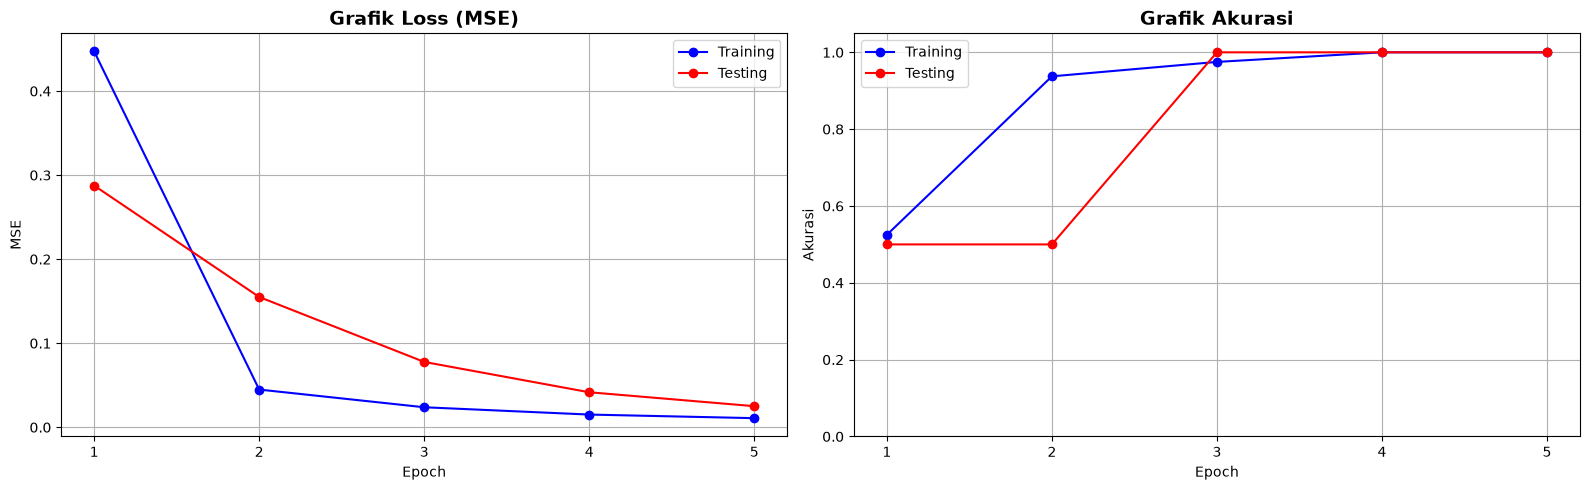


[ Tabel Hasil Training & Testing per Epoch ]


,Epoch,MSE Training,MSE Testing,Akurasi Training,Akurasi Testing
0,1,0.44715463432,0.28755157750,0.52500000000,0.50000000000
1,2,0.04486284222,0.15501014204,0.93750000000,0.50000000000
2,3,0.02381170207,0.07774028205,0.97500000000,1.00000000000
3,4,0.01511583879,0.04165460637,1.00000000000,1.00000000000
4,5,0.01083626261,0.02509920824,1.00000000000,1.00000000000


In [6]:
# ============================================================
# 6. VISUALISASI & REKAP HASIL PER EPOCH
# ============================================================
ep = range(1, EPOCHS + 1)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(ep, history['train_mse'], 'b-o', label='Training')
plt.plot(ep, history['test_mse'],  'r-o', label='Testing')
plt.title('Grafik Loss (MSE)', fontsize=14, fontweight='bold')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.xticks(list(ep))
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(ep, history['train_acc'], 'b-o', label='Training')
plt.plot(ep, history['test_acc'],  'r-o', label='Testing')
plt.title('Grafik Akurasi', fontsize=14, fontweight='bold')
plt.xlabel('Epoch'); plt.ylabel('Akurasi'); plt.ylim(0, 1.05); plt.xticks(list(ep))
plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

df_summary = pd.DataFrame({
    'Epoch': list(ep),
    'MSE Training': history['train_mse'],
    'MSE Testing':  history['test_mse'],
    'Akurasi Training': history['train_acc'],
    'Akurasi Testing':  history['test_acc'],
})
print("\n[ Tabel Hasil Training & Testing per Epoch ]")
display(df_summary)